<a href="https://colab.research.google.com/github/MankotiaGit/Statistical-Foundation-of-Data-Sciences-/blob/main/SFDS_PRACTICAL_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Installing the required libraries.

Step 2: Importing the necessary libraries.

Step 3: Loading and cleaning the sunspot dataset.

Step 4: Plotting sunspot data over the years.

Step 5: Creating 12-year solar cycles.

Step 6: Fitting the Gamma distribution.

Step 7: Plotting the histogram of sunspot counts.

Step 8: Comparing observed data with the Gamma distribution.

Step 9: Defining the Gamma model and performing MCMC sampling.

Step 10: Visualising the first 50, all and last 50 MCMC samples.

Step 11: Removing burn-in samples.

Step 12: Plotting trace graphs and histograms of parameters a and b.

Step 13: Checking MCMC convergence.

Step 14: Estimating the parameters a and b.

Step 15: Predicting future sunspot counts.

Step 16: Visualising the predicted sunspot distribution.

In [17]:
!pip install pymc arviz

Installing required libraries.

Step 1. Load and plot sunspot data

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from scipy.stats import gamma

print("Libraries imported successfully")

Libraries imported successfully


	Importing necessary libraries.

In [19]:
url = "https://www.sidc.be/SILSO/DATA/SN_m_tot_V2.0.csv"

df = pd.read_csv(
    url,
    sep=";",
    header=None,
    comment="#"
)

df = df.iloc[:, :7]

df.columns = [
    "Year", "Month", "Date",
    "Sunspots", "Std", "Observations", "Indicator"
]

# Convert columns into numeric values
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Month"] = pd.to_numeric(df["Month"], errors="coerce")
df["Sunspots"] = pd.to_numeric(df["Sunspots"], errors="coerce")

# Remove missing values
df = df.dropna(subset=["Year", "Month", "Sunspots"])

# Select January 1749 to November 2018
df = df[
    ((df["Year"] > 1749) |
     ((df["Year"] == 1749) & (df["Month"] >= 1))) &
    ((df["Year"] < 2018) |
     ((df["Year"] == 2018) & (df["Month"] <= 11)))
]

# Remove missing observations (-1)
df = df[df["Sunspots"] >= 0].copy()

# Create datetime column
df["Date"] = pd.to_datetime(
    dict(year=df["Year"], month=df["Month"], day=1)
)

df = df.reset_index(drop=True)

print(df.head())
print("\nTotal observations:", len(df))
print("\nDataset information:")
print(df.info())

   Year  Month       Date  Sunspots  Std  Observations  Indicator
0  1749      1 1749-01-01      96.7 -1.0            -1          1
1  1749      2 1749-02-01     104.3 -1.0            -1          1
2  1749      3 1749-03-01     116.7 -1.0            -1          1
3  1749      4 1749-04-01      92.8 -1.0            -1          1
4  1749      5 1749-05-01     141.7 -1.0            -1          1

Total observations: 3239

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3239 entries, 0 to 3238
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Year          3239 non-null   int64         
 1   Month         3239 non-null   int64         
 2   Date          3239 non-null   datetime64[ns]
 3   Sunspots      3239 non-null   float64       
 4   Std           3239 non-null   float64       
 5   Observations  3239 non-null   int64         
 6   Indicator     3239 non-null   int64         


	Loading and cleaning the sunspot dataset.

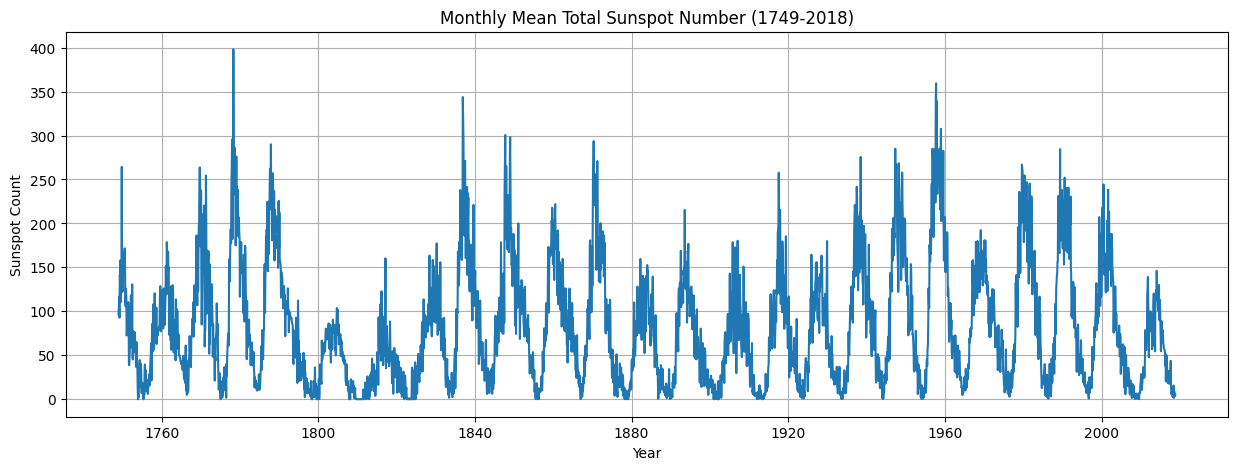

In [20]:
plt.figure(figsize=(15, 5))

plt.plot(df["Date"], df["Sunspots"])

plt.title("Monthly Mean Total Sunspot Number (1749-2018)")
plt.xlabel("Year")
plt.ylabel("Sunspot Count")
plt.grid(True)

plt.show()

Plotting sunspot data over the years.

Step 2. Model the phenomenon using Gamma distribution

In [21]:
cycle_length = 12 * 12  # 144 months

df["Cycle"] = np.arange(len(df)) // cycle_length

df["Cycle_Month"] = np.arange(len(df)) % cycle_length

print(df[["Date", "Sunspots", "Cycle", "Cycle_Month"]].head(15))

         Date  Sunspots  Cycle  Cycle_Month
0  1749-01-01      96.7      0            0
1  1749-02-01     104.3      0            1
2  1749-03-01     116.7      0            2
3  1749-04-01      92.8      0            3
4  1749-05-01     141.7      0            4
5  1749-06-01     139.2      0            5
6  1749-07-01     158.0      0            6
7  1749-08-01     110.5      0            7
8  1749-09-01     126.5      0            8
9  1749-10-01     125.8      0            9
10 1749-11-01     264.3      0           10
11 1749-12-01     142.0      0           11
12 1750-01-01     122.2      0           12
13 1750-02-01     126.5      0           13
14 1750-03-01     148.7      0           14


Creating 12-year solar cycles.

In [22]:
sunspot_data = df["Sunspots"].values

positive_data = sunspot_data[sunspot_data > 0]

# Fit Gamma distribution
a_fit, loc_fit, b_fit = gamma.fit(
    positive_data,
    floc=0
)

print("Gamma Distribution Parameters")
print("Shape (a):", a_fit)
print("Scale (b):", b_fit)

Gamma Distribution Parameters
Shape (a): 1.1742848202497331
Scale (b): 71.64020804539345


	Fitting the Gamma distribution.

Step 3. Plot histogram of sunspot counts

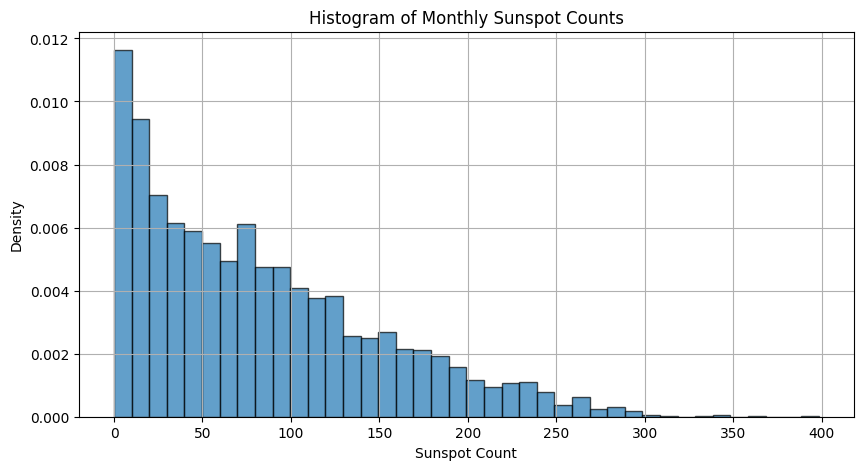

In [23]:
plt.figure(figsize=(10, 5))

plt.hist(
    sunspot_data,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.title("Histogram of Monthly Sunspot Counts")
plt.xlabel("Sunspot Count")
plt.ylabel("Density")
plt.grid(True)

plt.show()

Plotting the histogram of sunspot counts.

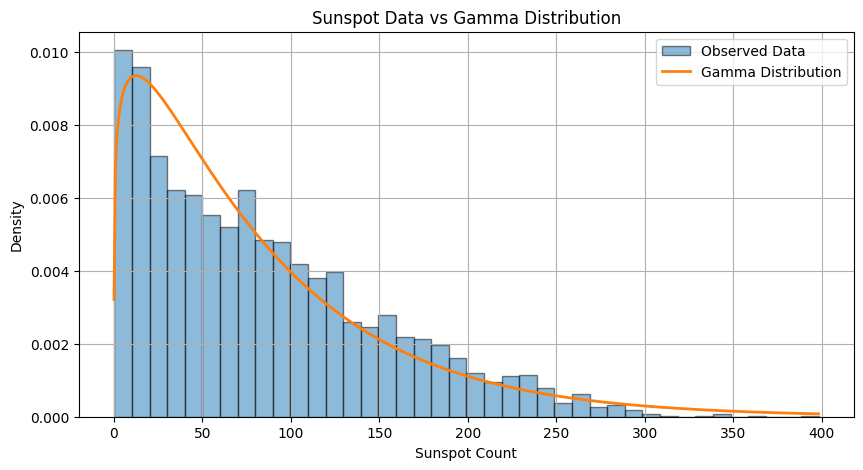

In [24]:
x = np.linspace(0.01, max(positive_data), 500)

plt.figure(figsize=(10, 5))

plt.hist(
    positive_data,
    bins=40,
    density=True,
    alpha=0.5,
    edgecolor="black",
    label="Observed Data"
)

plt.plot(
    x,
    gamma.pdf(x, a_fit, loc=0, scale=b_fit),
    linewidth=2,
    label="Gamma Distribution"
)

plt.title("Sunspot Data vs Gamma Distribution")
plt.xlabel("Sunspot Count")
plt.ylabel("Density")
plt.legend()
plt.grid(True)

plt.show()

	Comparing observed data with the Gamma distribution.

Step 4. MCMC sampling with a = 4 and b = 10

In [25]:
with pm.Model() as model:

    # Define prior distributions
    a = pm.HalfNormal("a", sigma=10, initval=4)

    b = pm.HalfNormal("b", sigma=50, initval=10)

    # Gamma likelihood
    sunspot_obs = pm.Gamma(
        "sunspot_obs",
        alpha=a,
        beta=1/b,
        observed=positive_data
    )

    # Future observation
    future_sunspot = pm.Gamma(
        "future_sunspot",
        alpha=a,
        beta=1/b
    )

    # Perform MCMC sampling
    trace = pm.sample(
        draws=2000,
        tune=1000,
        chains=2,
        cores=2,
        random_seed=42,
        return_inferencedata=True
    )

print("MCMC sampling completed successfully!")

Output()

MCMC sampling completed successfully!


	Defining the Gamma model and performing MCMC sampling.

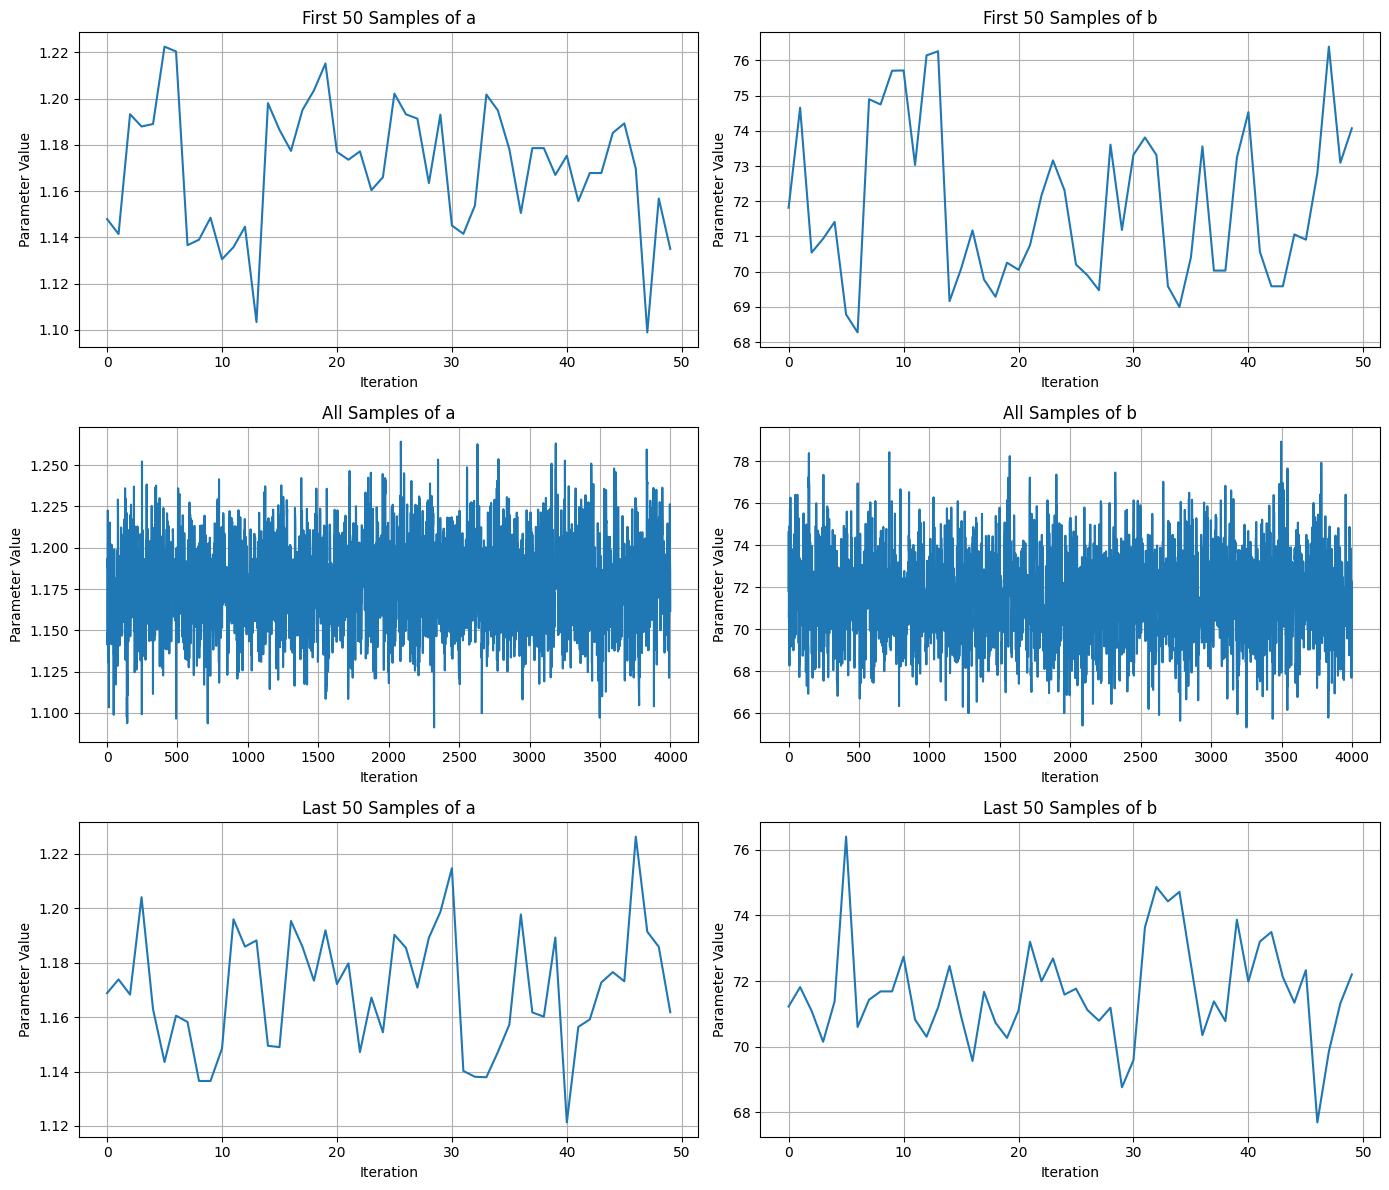

In [26]:
a_samples = trace.posterior["a"].values.flatten()
b_samples = trace.posterior["b"].values.flatten()

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# First 50 samples
axes[0, 0].plot(a_samples[:50])
axes[0, 0].set_title("First 50 Samples of a")

axes[0, 1].plot(b_samples[:50])
axes[0, 1].set_title("First 50 Samples of b")

# All samples
axes[1, 0].plot(a_samples)
axes[1, 0].set_title("All Samples of a")

axes[1, 1].plot(b_samples)
axes[1, 1].set_title("All Samples of b")

# Last 50 samples
axes[2, 0].plot(a_samples[-50:])
axes[2, 0].set_title("Last 50 Samples of a")

axes[2, 1].plot(b_samples[-50:])
axes[2, 1].set_title("Last 50 Samples of b")

for ax in axes.flat:
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Parameter Value")
    ax.grid(True)

plt.tight_layout()
plt.show()

Visualising the first 50, all and last 50 MCMC samples.

Step 5. Visualise traces of a and b and their histograms

In [27]:
burn_in = 1000

a_posterior = trace.posterior["a"].values[:, burn_in:].flatten()

b_posterior = trace.posterior["b"].values[:, burn_in:].flatten()

print("Samples after burn-in:", len(a_posterior))
print("Samples after burn-in:", len(b_posterior))

Samples after burn-in: 2000
Samples after burn-in: 2000


Removing burn-in samples.

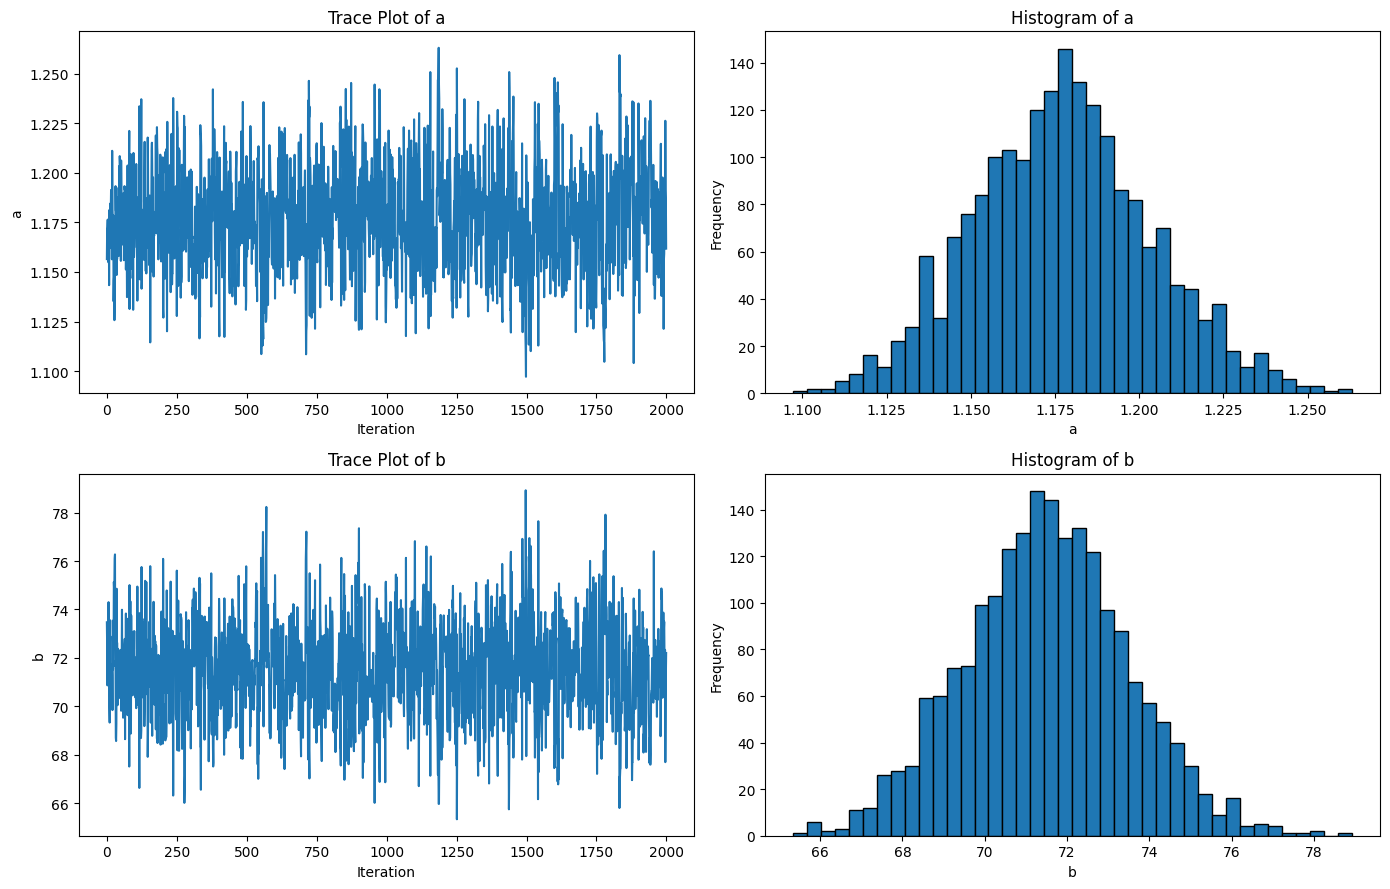

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Trace plot of a
axes[0, 0].plot(a_posterior)
axes[0, 0].set_title("Trace Plot of a")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel("a")

# Histogram of a
axes[0, 1].hist(a_posterior, bins=40, edgecolor="black")
axes[0, 1].set_title("Histogram of a")
axes[0, 1].set_xlabel("a")
axes[0, 1].set_ylabel("Frequency")

# Trace plot of b
axes[1, 0].plot(b_posterior)
axes[1, 0].set_title("Trace Plot of b")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("b")

# Histogram of b
axes[1, 1].hist(b_posterior, bins=40, edgecolor="black")
axes[1, 1].set_title("Histogram of b")
axes[1, 1].set_xlabel("b")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

	Plotting parameter traces and histograms.

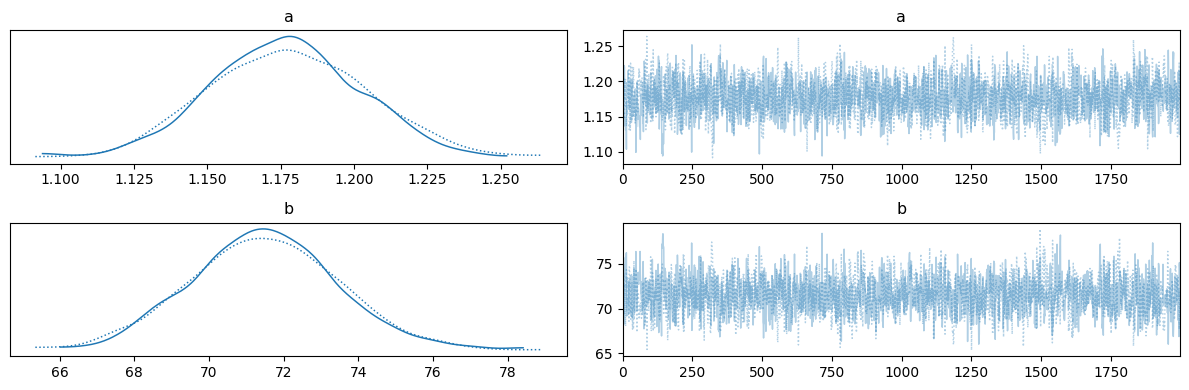

     mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a   1.177  0.026   1.131    1.228      0.001    0.000    1614.0    1659.0   
b  71.477  1.981  67.680   75.105      0.047    0.037    1776.0    1935.0   

   r_hat  
a    1.0  
b    1.0  


In [29]:
az.plot_trace(
    trace,
    var_names=["a", "b"]
)

plt.tight_layout()
plt.show()

print(az.summary(trace, var_names=["a", "b"]))

	Checking MCMC convergence.

Step 6. Prediction of a and b

In [30]:
print("PREDICTED GAMMA PARAMETERS")

print("\nParameter a:")
print("Mean:", np.mean(a_posterior))
print("Median:", np.median(a_posterior))
print("Standard Deviation:", np.std(a_posterior))
print("95% Credible Interval:",
      np.percentile(a_posterior, [2.5, 97.5]))

print("\nParameter b:")
print("Mean:", np.mean(b_posterior))
print("Median:", np.median(b_posterior))
print("Standard Deviation:", np.std(b_posterior))
print("95% Credible Interval:",
      np.percentile(b_posterior, [2.5, 97.5]))

PREDICTED GAMMA PARAMETERS

Parameter a:
Mean: 1.1771624647274594
Median: 1.1770381476314233
Standard Deviation: 0.026325458209478667
95% Credible Interval: [1.12697207 1.23020163]

Parameter b:
Mean: 71.47780111121709
Median: 71.48941667868456
Standard Deviation: 1.9906269319622893
95% Credible Interval: [67.59326841 75.40252823]


	Estimating the parameters a and b.

In [31]:
with model:
    prediction = pm.sample_posterior_predictive(
        trace,
        var_names=["future_sunspot"],
        random_seed=42
    )

predicted_values = (
    prediction.posterior_predictive["future_sunspot"]
    .values.flatten()
)

print("Predicted Sunspot Count")
print("Mean:", np.mean(predicted_values))
print("Median:", np.median(predicted_values))

print("95% Prediction Interval:",
      np.percentile(predicted_values, [2.5, 97.5]))

Output()

Predicted Sunspot Count
Mean: 83.71840534838019
Median: 62.09907301577083
95% Prediction Interval: [  3.48463936 281.00768085]


	Predicting future sunspot counts.

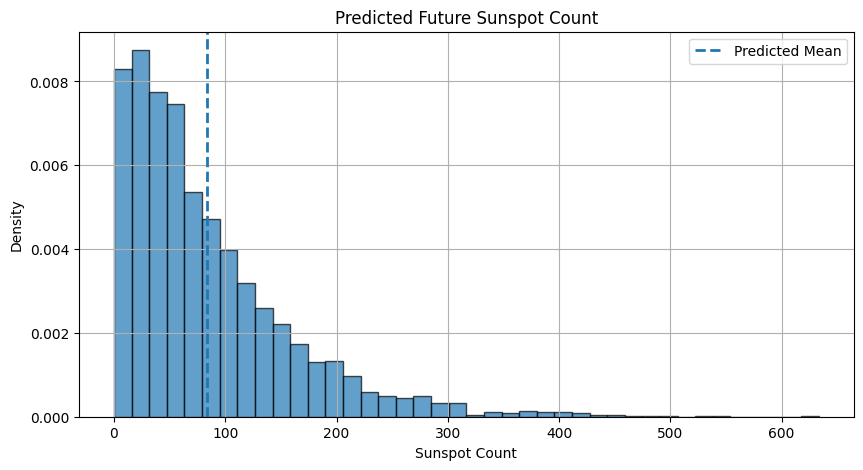

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(
    predicted_values,
    bins=40,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    np.mean(predicted_values),
    linestyle="--",
    linewidth=2,
    label="Predicted Mean"
)

plt.title("Predicted Future Sunspot Count")
plt.xlabel("Sunspot Count")
plt.ylabel("Density")
plt.legend()
plt.grid(True)

plt.show()

Visualising the predicted sunspot distribution.